### This code illustrates how to determine the time a CO2 molecule spent in a solvation cage

### Prerequisite:
* DiffusionCoefficient

### Package Required:
* numpy
* mdtraj
* matplotlib

### Note: If you don't have the packages listed above installed, then you can type in the following commands in the terminal
* conda install numpy
* conda install -c conda-forge mdtraj
* conda install matplotlib

### File Required:
* A trajectory file (.h5 or .dcd)
* A toplogy file (.pdb)

* Note: Here, I use a trajectory that contains only one CO2 molecule as an example
    *  /pikachu/homes/zhuo/haverford/code_example/EMIM_NTF2.dcd
    *  /pikachu/homes/zhuo/haverford/code_example/EMIM_NTF2.pdb

### Background
* Non-Gaussian Parameter
    * Non-Gaussian parameter $\alpha_2(t)$ describes how the particle displacement deviates from a normal (Gaussian) distribution, which can be used to study dynamical heterogeneity of the diffusing particle. To calculate the $\alpha_2(t)$ term, the following equation is applied:
    * $$\alpha_2(t) = \frac{3\left\langle\left(\vec{r}_i(t + t_0) - \vec{r}_i(t_0)\right)^4\right\rangle}{5\left\langle\left(\vec{r}_i(t + t_0) - \vec{r}_i(t_0)\right)^2\right\rangle^2} - 1$$
    * Here, the denominator $\left\langle\left(\vec{r}_i(t + t_0) - \vec{r}_i(t_0)\right)^2\right\rangle$ represents the mean squared displacement, and the numerator $\left\langle\left(\vec{r}_i(t + t_0) - \vec{r}_i(t_0)\right)^4\right\rangle$ represents the mean of the fourth order of the displacement.
    * When t = 0, by definition, $\alpha_2(t)$ = 0;
    * When $\alpha_2(t)$ reaches its maximum ( $t=\tau_{\alpha_2}$ ), it represents the point of peak heterogeneity in the system, which indicates the characteristic time requires for the $CO_2$ molecule to escape from its local solvation cage.

### The Code:

1. Import the required package

In [3]:
import numpy as np
import mdtraj as md
import matplotlib.pyplot as plt
import os
import math

2. Load the trajectory file 

In [4]:
traj = md.load('/pikachu/homes/zhuo/haverford/code_example/EMIM_NTF2.dcd',top='/pikachu/homes/zhuo/haverford/code_example/EMIM_NTF2.pdb')
topology = traj.topology
traj
topology

<mdtraj.Topology with 3 chains, 522 residues, 8734 atoms, 8468 bonds at 0x7f4428509220>

3. Calculate the center of mass for each CO2 molecule in each frame

In [42]:
pos_com = []
res_name = "OCO"
for i, res in enumerate(topology.residues):
    if res.name == res_name:
        atom_indices = [atom.index for atom in res.atoms]
        subtraj = traj.atom_slice(atom_indices)
        com = md.compute_center_of_mass(subtraj)
        pos_com.append(com)
xyz = np.asarray(pos_com).transpose(1, 0, 2)

4. Define the time separation

In [43]:
n_frames = traj.n_frames
timestep = 10 # ps
taus_in_frame = np.arange(n_frames) * timestep

5. Calculate the mean square displacement and mean quartic displacement

In [50]:
msds = np.zeros(len(taus_in_frame))
quartic = np.zeros(len(taus_in_frame))

for i, tau in enumerate(range(0, n_frames)):
    if tau == 0:
        msds[i] = 0.0
        quartic[i] = 0.0
    else:
        disp = xyz[tau:] - xyz[:-tau]
        dists_squared = np.sum(disp**2, axis=-1)  
        dists_quartic = dists_squared**2
        msds[i] = np.mean(dists_squared)
        quartic[i] = np.mean(dists_quartic)

6. Calculate the caging time

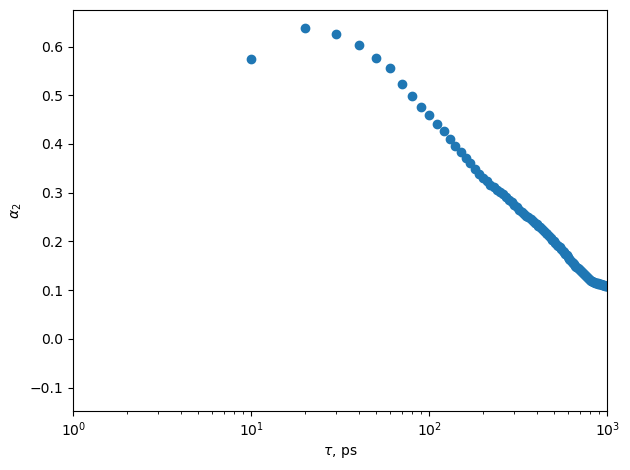

In [51]:
alpha_2 = np.zeros_like(msds)
alpha_2[1:] = (0.6 * quartic[1:]) / (msds[1:]**2) - 1
plt.scatter(taus_in_frame, alpha_2)
plt.xlim(1,1000)
plt.xscale('log')
plt.xlabel(r'$\tau$, ps')
plt.ylabel(r'$\alpha_{2}$')
plt.tight_layout()
plt.show()

In [53]:
peak_index = np.argmax(alpha_2)
caging_time = taus_in_frame[peak_index]
print(f"The caging time is {caging_time} ps")

The caging time is 20 ps
